In [9]:
# Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# Import Libraries

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from PIL import Image

In [ ]:
import json
import pandas as pd

json_path = "/content/drive/MyDrive/Nishat_Nayla_MSC_Thesis/Datasets/Breast_Cancer/metadata.xlsx"

with open(json_path, 'r') as f:
    data = json.load(f)

print(type(data))

<class 'dict'>


In [ ]:
print(data.keys())

dict_keys(['@context', 'alternateName', 'conformsTo', 'license', 'distribution', 'version', 'keywords', 'isAccessibleForFree', 'includedInDataCatalog', 'creator', 'publisher', 'thumbnailUrl', 'dateModified', '@type', 'name', 'url', 'description'])


In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Loading JSON metadata file

json_path = "/content/drive/MyDrive/Nishat_Nayla_MSC_Thesis/Datasets/Breast_Cancer/dmid-breast-cancer-mammography-dataset-metadata.json"

with open(json_path, 'r') as f:
    data = json.load(f)

# Basic Information

print("========== BASIC INFORMATION ==========\n")

print("Dataset Type :", type(data))
print("Total Metadata Fields :", len(data))

print("\nMetadata Keys:\n")

for key in data.keys():
    print(key)

# Creating Metadata DataFrame

metadata_df = pd.DataFrame({
    "Field": list(data.keys()),
    "Value_Type": [type(v).__name__ for v in data.values()]
})

print("\n========== METADATA DATAFRAME ==========\n")

print(metadata_df)

# Text Length Analysis

text_lengths = {}

for key, value in data.items():

    if isinstance(value, str):
        text_lengths[key] = len(value)

text_length_df = pd.DataFrame({
    "Field": list(text_lengths.keys()),
    "Character_Length": list(text_lengths.values())
})

print("\n========== TEXT LENGTH ANALYSIS ==========\n")

print(text_length_df)

# List Type Analysis

print("\n========== LIST TYPE FIELD ANALYSIS ==========\n")

for key, value in data.items():

    if isinstance(value, list):
        print(f"{key} --> Total Items : {len(value)}")

# Keyword Analysis

keywords = data.get("keywords", [])

print("\n========== KEYWORD ANALYSIS ==========\n")

print("Total Keywords :", len(keywords))

for keyword in keywords:
    print(keyword)

# Distribution Analysis

distribution = data.get("distribution", [])

print("\n========== DISTRIBUTION ANALYSIS ==========\n")

print("Total Distribution Entries :", len(distribution))

print(distribution)

# Creator Information

print("\n========== CREATOR INFORMATION ==========\n")

print(data.get("creator"))

# Publisher Information

print("\n========== PUBLISHER INFORMATION ==========\n")

print(data.get("publisher"))

# Dataset Summary

print("\n========== DATASET SUMMARY ==========\n")

print("Dataset Name :", data.get("name"))
print("Dataset Type :", data.get("@type"))
print("Version :", data.get("version"))
print("License :", data.get("license"))
print("Accessible For Free :", data.get("isAccessibleForFree"))
print("Date Modified :", data.get("dateModified"))

print("\nDescription :\n")

print(data.get("description"))

# Plot 1 : Metadata Value Types

plt.figure(figsize=(8,5))

metadata_df['Value_Type'].value_counts().plot(kind='bar')

plt.title("Metadata Value Type Distribution")
plt.xlabel("Value Types")
plt.ylabel("Count")

plt.show()

# Plot 2 : Text Length Analysis

plt.figure(figsize=(12,5))

plt.bar(text_lengths.keys(), text_lengths.values())

plt.xticks(rotation=90)

plt.title("Metadata Text Length Analysis")
plt.xlabel("Metadata Fields")
plt.ylabel("Character Length")

plt.show()

# Plot 3 : Keyword Visualization

if len(keywords) > 0:

    plt.figure(figsize=(12,5))

    plt.bar(range(len(keywords)), [1]*len(keywords))

    plt.xticks(range(len(keywords)), keywords, rotation=90)

    plt.title("Dataset Keywords")

    plt.show()

# Plot 4 : Field Length Heatmap

field_lengths = []

for value in data.values():

    if isinstance(value, str):
        field_lengths.append(len(value))

    elif isinstance(value, list):
        field_lengths.append(len(value))

    elif isinstance(value, dict):
        field_lengths.append(len(value))

    else:
        field_lengths.append(1)

heatmap_df = pd.DataFrame({
    "Field": list(data.keys()),
    "Length": field_lengths
})

plt.figure(figsize=(12,4))

sns.heatmap(
    heatmap_df[['Length']].T,
    annot=True,
    cmap='Blues',
    xticklabels=heatmap_df['Field']
)

plt.title("Metadata Field Length Heatmap")

plt.show()

========== BASIC INFORMATION ==========

Dataset Shape : (677, 8)

Columns:

Index(['1st column:', ' Image reference number.', 'Unnamed: 2', 'Unnamed: 3',
       'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'],
      dtype='object')

Data Types:

1st column:                  object
 Image reference number.     object
Unnamed: 2                   object
Unnamed: 3                   object
Unnamed: 4                   object
Unnamed: 5                  float64
Unnamed: 6                  float64
Unnamed: 7                   object
dtype: object

Dataset Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 677 entries, 0 to 676
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   1st column:               654 non-null    object 
 1    Image reference number.  653 non-null    object 
 2   Unnamed: 2                647 non-null    object 
 3   Unnamed: 3                664 non-null    o

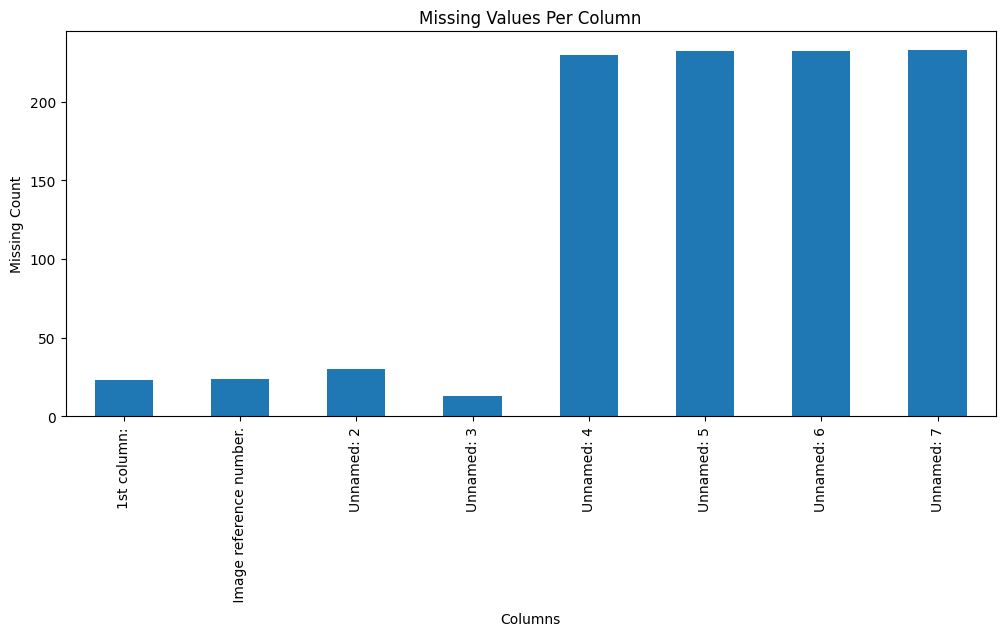

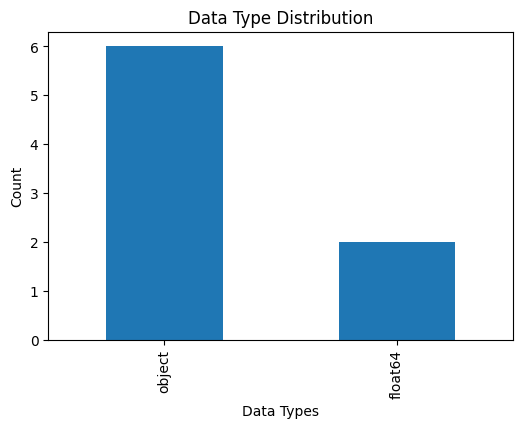

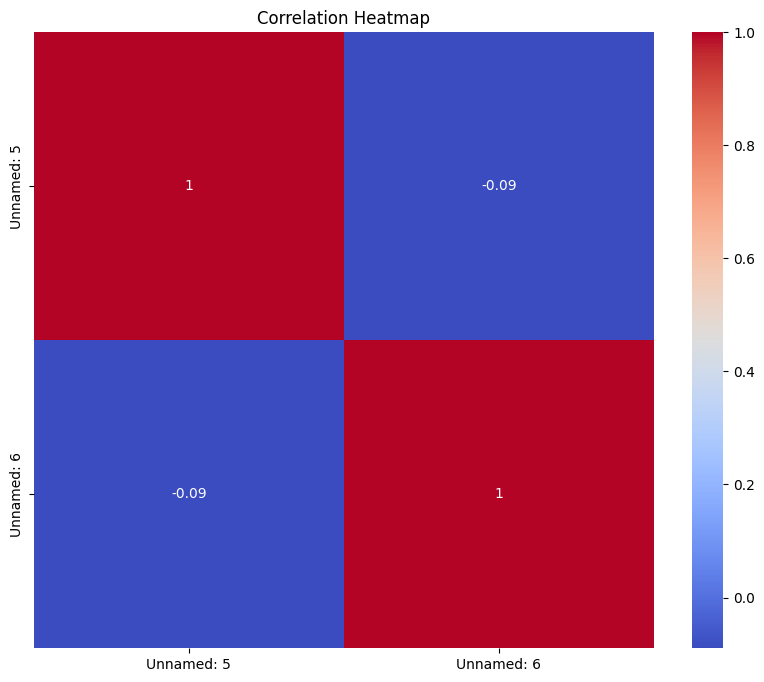

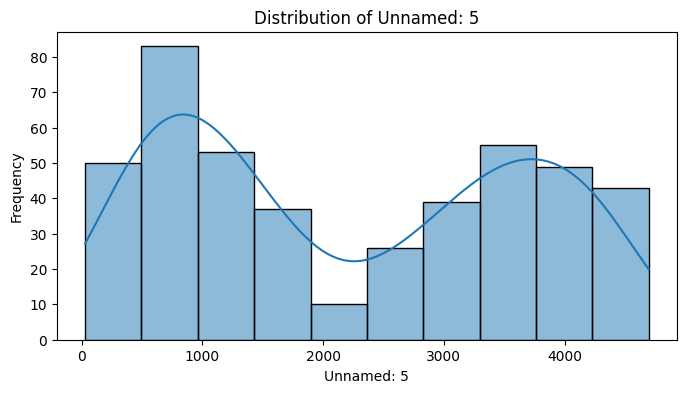

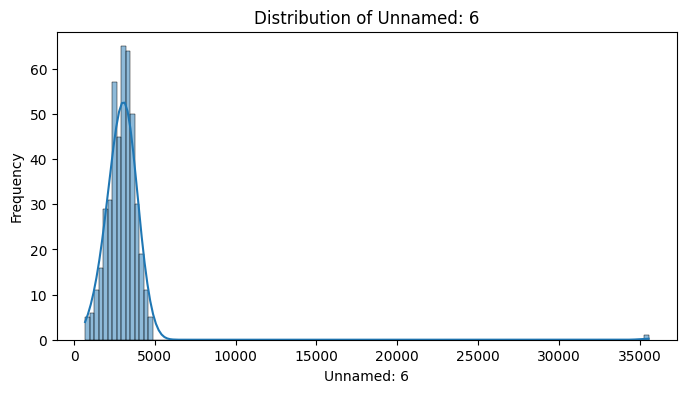

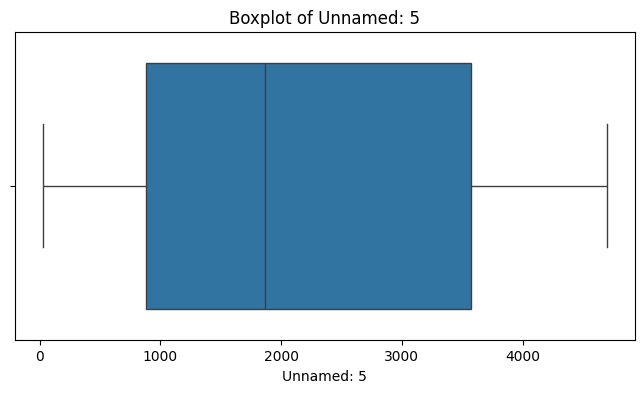

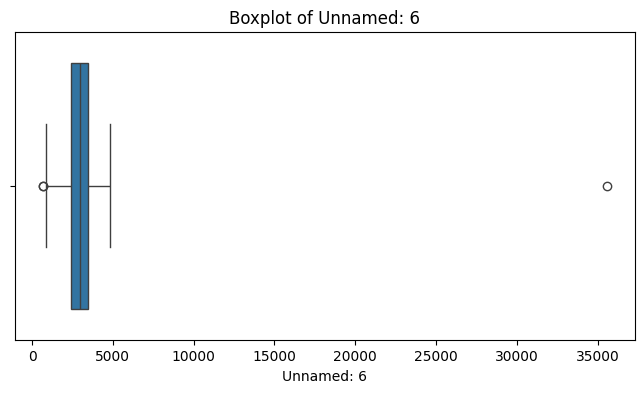

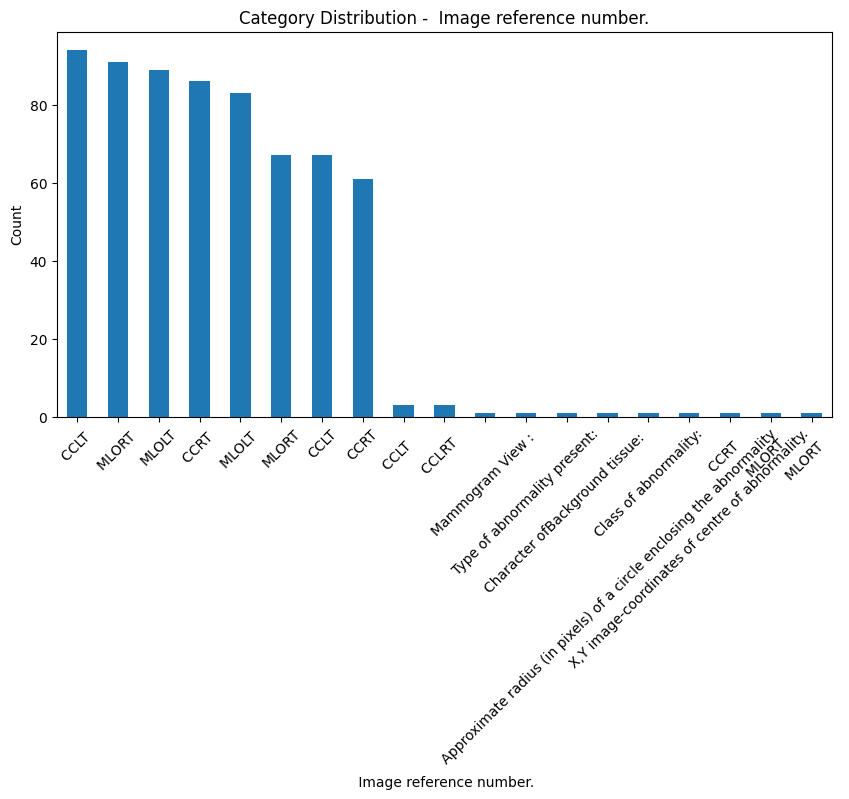

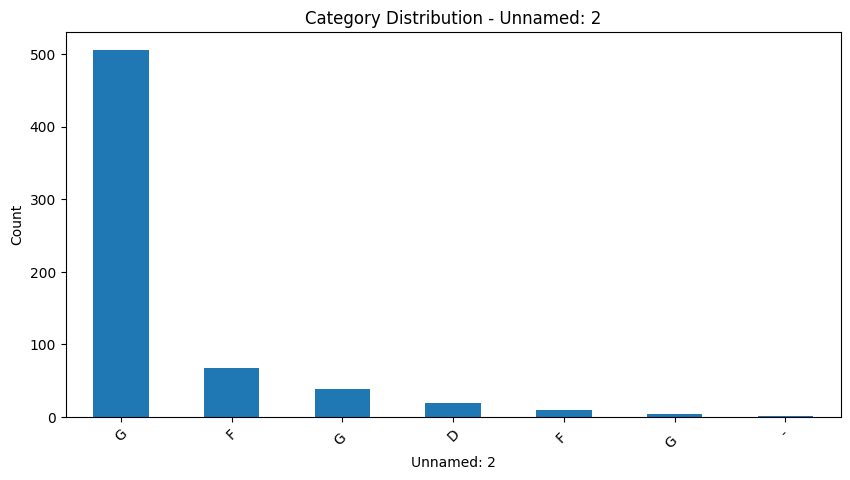

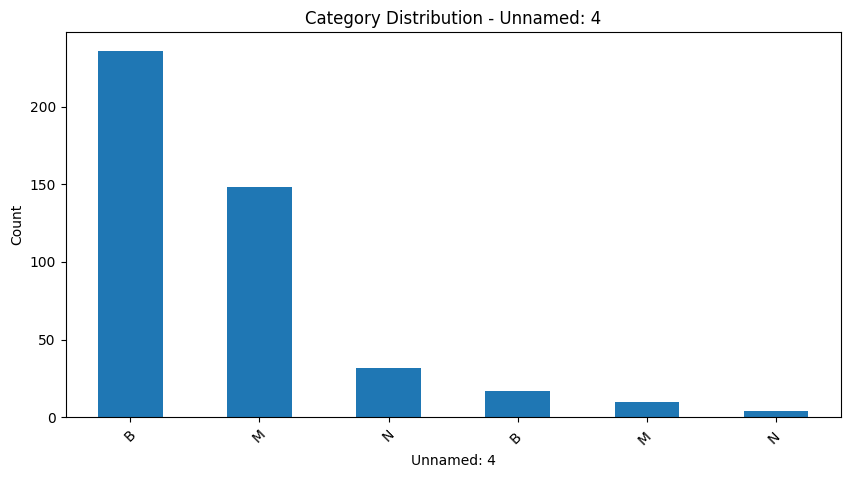


========== FINAL SUMMARY ==========

Total Rows : 677
Total Columns : 8

Numerical Columns : 2
Categorical Columns : 6

Memory Usage :
Index                         132
1st column:                 37268
 Image reference number.    36287
Unnamed: 2                  33367
Unnamed: 3                  36155
Unnamed: 4                  29741
Unnamed: 5                   5416
Unnamed: 6                   5416
Unnamed: 7                  23454
dtype: int64


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading Metadata Excel File

file_path = "/content/drive/MyDrive/Nishat_Nayla_MSC_Thesis/Datasets/Breast_Cancer/Metadata.xlsx"

df = pd.read_excel(file_path)

# Basic Information

print("========== BASIC INFORMATION ==========\n")

print("Dataset Shape :", df.shape)

print("\nColumns:\n")
print(df.columns)

print("\nData Types:\n")
print(df.dtypes)

print("\nDataset Info:\n")
print(df.info())

# First Few Rows

print("\n========== FIRST 5 ROWS ==========\n")

print(df.head())

# Missing Value Analysis

print("\n========== MISSING VALUES ==========\n")

missing_values = df.isnull().sum()

print(missing_values)

# Missing Value Percentage

missing_percentage = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": missing_percentage
})

print("\n========== MISSING VALUE PERCENTAGE ==========\n")

print(missing_df)

# Duplicate Analysis

print("\n========== DUPLICATE ANALYSIS ==========\n")

print("Total Duplicate Rows :", df.duplicated().sum())

# Statistical Summary

print("\n========== NUMERICAL STATISTICS ==========\n")

print(df.describe())

# Categorical Summary

print("\n========== CATEGORICAL STATISTICS ==========\n")

print(df.describe(include='object'))

# Unique Values Per Column

print("\n========== UNIQUE VALUE COUNT ==========\n")

for col in df.columns:
    print(f"{col} --> {df[col].nunique()} unique values")

# Plot 1 : Missing Values

plt.figure(figsize=(12,5))

missing_values.plot(kind='bar')

plt.title("Missing Values Per Column")
plt.xlabel("Columns")
plt.ylabel("Missing Count")

plt.xticks(rotation=90)

plt.show()

# Plot 2 : Data Type Distribution

dtype_counts = df.dtypes.astype(str).value_counts()

plt.figure(figsize=(6,4))

dtype_counts.plot(kind='bar')

plt.title("Data Type Distribution")
plt.xlabel("Data Types")
plt.ylabel("Count")

plt.show()

# Plot 3 : Correlation Heatmap

numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] > 1:

    plt.figure(figsize=(10,8))

    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap='coolwarm'
    )

    plt.title("Correlation Heatmap")

    plt.show()

# Plot 4 : Distribution of Numerical Features

for col in numeric_df.columns:

    plt.figure(figsize=(8,4))

    sns.histplot(df[col].dropna(), kde=True)

    plt.title(f"Distribution of {col}")

    plt.xlabel(col)

    plt.ylabel("Frequency")

    plt.show()

# Plot 5 : Boxplots for Numerical Features

for col in numeric_df.columns:

    plt.figure(figsize=(8,4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")

    plt.show()

# Plot 6 : Category Distribution for Object Columns

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:

    if df[col].nunique() <= 20:

        plt.figure(figsize=(10,5))

        df[col].value_counts().plot(kind='bar')

        plt.title(f"Category Distribution - {col}")

        plt.xlabel(col)
        plt.ylabel("Count")

        plt.xticks(rotation=45)

        plt.show()

# Final Summary

print("\n========== FINAL SUMMARY ==========\n")

print("Total Rows :", df.shape[0])
print("Total Columns :", df.shape[1])

print("\nNumerical Columns :", len(numeric_df.columns))
print("Categorical Columns :", len(categorical_cols))

print("\nMemory Usage :")
print(df.memory_usage(deep=True))